In [1]:
import pandas as pd

cols = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
"wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
"root_shell","su_attempted","num_root","num_file_creations","num_shells",
"num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
"srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
"same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
"dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
"dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
"dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
"label","difficulty"]

df = pd.read_csv("KDDTrain+.txt", header=None, names=cols)
print(df.shape)
df.head()

(125973, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [2]:
print(df["label"].value_counts().head(10))

label
normal         67343
neptune        41214
satan           3633
ipsweep         3599
portsweep       2931
smurf           2646
nmap            1493
back             956
teardrop         892
warezclient      890
Name: count, dtype: int64


In [3]:
df["target"] = df["label"].apply(lambda x: "normal" if x == "normal" else "attack")
print(df["target"].value_counts())

target
normal    67343
attack    58630
Name: count, dtype: int64


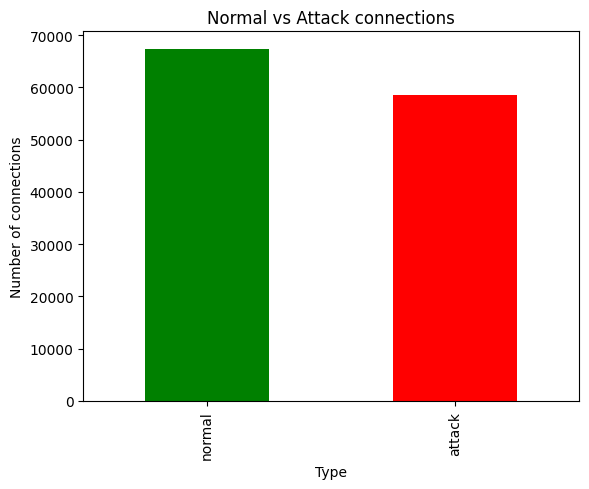

In [4]:
import matplotlib.pyplot as plt

df["target"].value_counts().plot(kind="bar", color=["green", "red"])
plt.title("Normal vs Attack connections")
plt.xlabel("Type")
plt.ylabel("Number of connections")
plt.show()

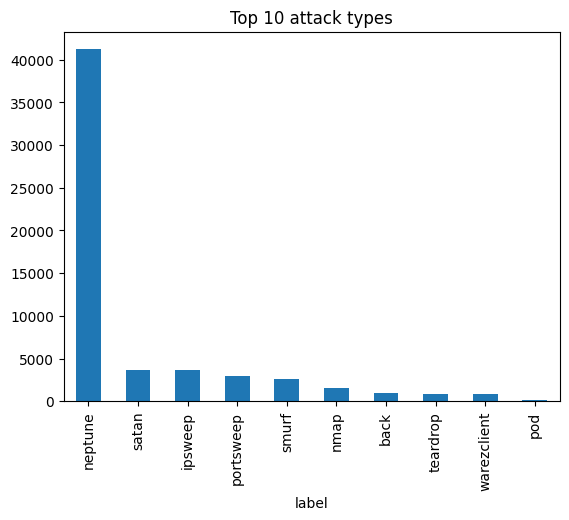

In [5]:
df[df["target"] == "attack"]["label"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 attack types")
plt.show()

In [6]:
X = df.drop(["label", "target", "difficulty"], axis=1)
X = pd.get_dummies(X)
y = df["target"]
print(X.shape)

(125973, 122)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), len(X_test))

100778 25195


In [8]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=50)
model.fit(X_train, y_train)
print("Training done!")

Training done!


In [9]:
from sklearn.metrics import accuracy_score

pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))

Accuracy: 0.9988886683865846


In [10]:
test = pd.read_csv("KDDTest+.txt", header=None, names=cols)
test["target"] = test["label"].apply(lambda x: "normal" if x == "normal" else "attack")

X_new = test.drop(["label", "target", "difficulty"], axis=1)
X_new = pd.get_dummies(X_new)
X_new = X_new.reindex(columns=X.columns, fill_value=0)
y_new = test["target"]

pred_new = model.predict(X_new)
print("Accuracy on KDDTest+:", accuracy_score(y_new, pred_new))

Accuracy on KDDTest+: 0.7810503903477644


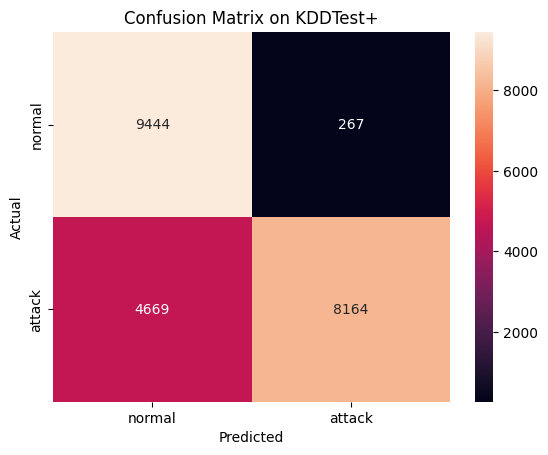

              precision    recall  f1-score   support

      attack       0.97      0.64      0.77     12833
      normal       0.67      0.97      0.79      9711

    accuracy                           0.78     22544
   macro avg       0.82      0.80      0.78     22544
weighted avg       0.84      0.78      0.78     22544



In [11]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_new, pred_new, labels=["normal", "attack"])
sns.heatmap(cm, annot=True, fmt="d", xticklabels=["normal", "attack"], yticklabels=["normal", "attack"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix on KDDTest+")
plt.show()

print(classification_report(y_new, pred_new))